<a href="https://colab.research.google.com/github/nigilsrisanth050806-png/unit-test-/blob/main/next_word_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kagglehub tensorflow pandas numpy scikit-learn matplotlib

In [ ]:
import kagglehub
import os

# Download latest version of the dataset
path = kagglehub.dataset_download(
    "ronikdedhia/next-word-prediction"
)

print("Path to dataset files:", path)

# Display downloaded files
for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

100%|██████████| 228k/228k [00:00<00:00, 55.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/ronikdedhia/next-word-prediction/versions/1
/root/.cache/kagglehub/datasets/ronikdedhia/next-word-prediction/versions/1/1661-0.txt


In [ ]:
import pandas as pd
import os
import glob

# Find files inside the downloaded folder
all_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Files found:", all_files)

# Find CSV files
csv_files = [
    file for file in all_files
    if file.lower().endswith(".csv")
]

# Find text files
txt_files = [
    file for file in all_files
    if file.lower().endswith(".txt")
]

sentences = []

if csv_files:

    print("CSV dataset found:", csv_files[0])

    df = pd.read_csv(csv_files[0])

    print("\nDataset preview:")
    print(df.head())

    print("\nColumn names:")
    print(df.columns.tolist())

    # Automatically identify a likely text column
    possible_columns = [
        "sentence",
        "sentences",
        "text",
        "content",
        "article"
    ]

    column_lookup = {
        col.lower().strip(): col
        for col in df.columns
    }

    text_column = next(
        (
            column_lookup[col]
            for col in possible_columns
            if col in column_lookup
        ),
        None
    )

    if text_column is None:
        # Fallback: choose the column with the most string data
        text_column = df.select_dtypes(
            include=["object", "string"]
        ).columns[0]

    sentences = (
        df[text_column]
        .dropna()
        .astype(str)
        .tolist()
    )

elif txt_files:

    print("Text dataset found:", txt_files[0])

    with open(
        txt_files[0],
        "r",
        encoding="utf-8"
    ) as file:
        text = file.read()

    sentences = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

else:

    raise ValueError(
        "CSV/TXT file not found. "
        "Check the displayed file names and dataset format."
    )

print("\nTotal text entries:", len(sentences))
print("\nFirst five entries:")

for sentence in sentences[:5]:
    print(sentence)

Files found: ['/root/.cache/kagglehub/datasets/ronikdedhia/next-word-prediction/versions/1/1661-0.txt']
Text dataset found: /root/.cache/kagglehub/datasets/ronikdedhia/next-word-prediction/versions/1/1661-0.txt

Total text entries: 9634

First five entries:
﻿
Project Gutenberg's The Adventures of Sherlock Holmes, by Arthur Conan Doyle
This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included


In [ ]:
import re

# Keep at most 10,000 text entries
sentences = sentences[:10000]

def clean_text(text):

    text = text.lower()

    # Keep English letters, numbers, apostrophes and spaces
    text = re.sub(r"[^a-z0-9'\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

cleaned_sentences = [
    clean_text(sentence)
    for sentence in sentences
]

# Remove empty and very short entries
cleaned_sentences = [
    sentence
    for sentence in cleaned_sentences
    if len(sentence.split()) >= 2
]

print("Sentences selected:", len(cleaned_sentences))

print("\nCleaned samples:")

for sentence in cleaned_sentences[:5]:
    print(sentence)

Sentences selected: 9346

Cleaned samples:
project gutenberg's the adventures of sherlock holmes by arthur conan doyle
this ebook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever you may copy it give it away or
re use it under the terms of the project gutenberg license included
with this ebook or online at www gutenberg net


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_VOCAB_SIZE = 10000

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(cleaned_sentences)

word_index = tokenizer.word_index

vocab_size = min(
    MAX_VOCAB_SIZE,
    len(word_index) + 1
)

print("Total unique words:", len(word_index))
print("Vocabulary size used:", vocab_size)

print("\nSample vocabulary:")

for word, index in list(word_index.items())[:20]:
    print(word, ":", index)

Total unique words: 8158
Vocabulary size used: 8159

Sample vocabulary:
<OOV> : 1
the : 2
and : 3
i : 4
to : 5
of : 6
a : 7
in : 8
that : 9
it : 10
you : 11
he : 12
was : 13
his : 14
is : 15
my : 16
have : 17
with : 18
as : 19
had : 20


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

input_sequences = []

for sentence in cleaned_sentences:

    token_list = tokenizer.texts_to_sequences(
        [sentence]
    )[0]

    # Generate progressively longer sequences
    for i in range(1, len(token_list)):

        sequence = token_list[:i + 1]

        input_sequences.append(sequence)

print("Total sequences:", len(input_sequences))

# Find maximum sequence length
max_sequence_len = max(
    len(sequence)
    for sequence in input_sequences
)

print("Maximum sequence length:", max_sequence_len)

# Pad all sequences to equal length
input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

# Input: all tokens except the last
X = input_sequences[:, :-1]

# Target: last token
y = input_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

Total sequences: 99615
Maximum sequence length: 19
X shape: (99615, 18)
y shape: (99615,)


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 79692
Testing samples: 19923


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(SEED)

model = Sequential([

    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),

    LSTM(128),

    Dropout(0.2),

    Dense(
        vocab_size,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")

Epoch 1/15
1121/1121 ━━━━━━━━━━━━━━━━━━━━ 95s 85ms/step - accuracy: 0.1162 - loss: 5.5468 - val_accuracy: 0.1266 - val_loss: 5.8199
Epoch 2/15
1121/1121 ━━━━━━━━━━━━━━━━━━━━ 96s 85ms/step - accuracy: 0.1321 - loss: 5.3024 - val_accuracy: 0.1324 - val_loss: 5.7802
Epoch 3/15
1121/1121 ━━━━━━━━━━━━━━━━━━━━ 93s 83ms/step - accuracy: 0.1454 - loss: 5.0858 - val_accuracy: 0.1365 - val_loss: 5.7839
Epoch 4/15
1121/1121 ━━━━━━━━━━━━━━━━━━━━ 93s 83ms/step - accuracy: 0.1575 - loss: 4.8846 - val_accuracy: 0.1380 - val_loss: 5.8160
Epoch 5/15
1121/1121 ━━━━━━━━━━━━━━━━━━━━ 94s 84ms/step - accuracy: 0.1699 - loss: 4.6974 - val_accuracy: 0.1404 - val_loss: 5.8599
Model training completed!


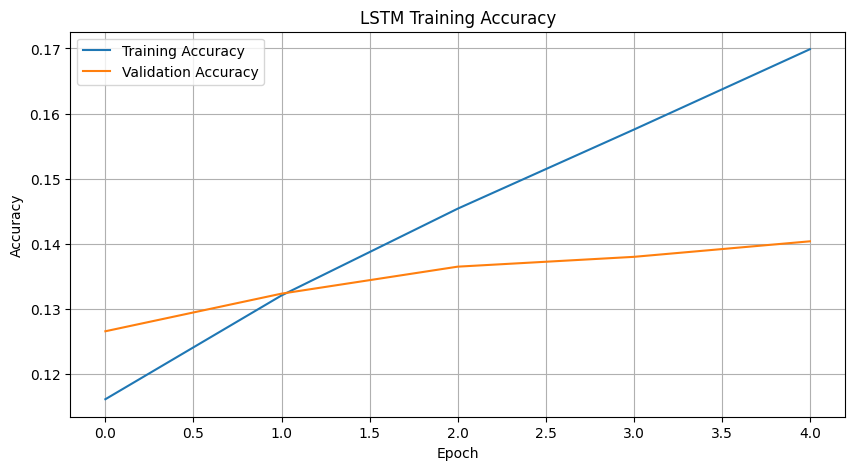

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import numpy as np

# Top-1 accuracy
test_loss, top1_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Top-1 Accuracy: {top1_accuracy * 100:.2f}%")

# Predict probabilities for the test set
test_probabilities = model.predict(
    X_test,
    verbose=0
)

# Get top-five word IDs
top5_indices = np.argsort(
    test_probabilities,
    axis=1
)[:, -5:]

# Calculate top-five accuracy
top5_accuracy = np.mean([
    target in predictions
    for target, predictions in zip(
        y_test,
        top5_indices
    )
])

print(f"Top-5 Accuracy: {top5_accuracy * 100:.2f}%")

Test Loss: 5.8653
Top-1 Accuracy: 12.74%
Top-5 Accuracy: 28.94%


In [ ]:
def predict_next_words(text, top_k=5):

    text = clean_text(text)

    token_list = tokenizer.texts_to_sequences(
        [text]
    )[0]

    if not token_list:
        return []

    # Keep only the most recent context words
    max_context = max_sequence_len - 1
    token_list = token_list[-max_context:]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding="pre"
    )

    probabilities = model.predict(
        token_list,
        verbose=0
    )[0]

    # Do not suggest padding or OOV token
    probabilities[0] = 0

    oov_id = tokenizer.word_index.get("<OOV>")

    if oov_id is not None and oov_id < len(probabilities):
        probabilities[oov_id] = 0

    top_indices = np.argsort(
        probabilities
    )[-top_k:][::-1]

    results = []

    for index in top_indices:

        word = tokenizer.index_word.get(index)

        if word is not None:
            results.append((
                word,
                float(probabilities[index])
            ))

    return results

In [ ]:
test_phrases = [
    "i want to",
    "machine learning is",
    "artificial intelligence can",
    "i am going to",
    "the weather is"
]

for phrase in test_phrases:

    predictions = predict_next_words(
        phrase,
        top_k=5
    )

    print("\nInput:", phrase)

    for rank, (word, probability) in enumerate(
        predictions,
        start=1
    ):
        print(
            f"{rank}. {word} "
            f"({probability * 100:.2f}%)"
        )


Input: i want to
1. be (7.90%)
2. the (4.40%)
3. me (3.73%)
4. you (3.16%)
5. see (2.77%)

Input: machine learning is
1. a (3.28%)
2. in (1.99%)
3. to (1.95%)
4. the (1.84%)
5. his (0.96%)

Input: artificial intelligence can
1. be (3.29%)
2. have (0.88%)
3. the (0.80%)
4. see (0.65%)
5. a (0.57%)

Input: i am going to
1. the (9.55%)
2. be (9.11%)
3. you (4.89%)
4. me (4.80%)
5. my (2.96%)

Input: the weather is
1. a (16.81%)
2. the (11.81%)
3. in (3.26%)
4. to (2.35%)
5. it (2.19%)


In [ ]:
model.save("next_word_lstm.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import pickle

with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!
